<a href="https://colab.research.google.com/github/zadigpedrono/zadigpedrono-DataScience-GenAI-Submissions/blob/main/Seminar2_Titanic_File_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from google.colab import files

# This will prompt you to select a file from your local machine to upload to Colab
uploaded = files.upload()

for fn in uploaded.keys():
  print('User uploaded file "{name}" with length {length} bytes'.format(
      name=fn, length=len(uploaded[fn])))

Saving titanic.csv to titanic.csv
User uploaded file "titanic.csv" with length 61194 bytes


In [3]:
import pandas as pd

In [4]:
import numpy as np

In [7]:
df = pd.read_csv('titanic.csv')

In [ ]:
df

In [8]:
# Clean the Titanic dataset

# 1. Drop duplicates if any
df = df.drop_duplicates()

# 2. Handle missing values
# Drop 'Cabin' column because it has too many missing values
if 'Cabin' in df.columns:
    df = df.drop(columns=['Cabin'])

# Impute missing 'Age' values with the median age
if 'Age' in df.columns:
    df['Age'] = df['Age'].fillna(df['Age'].median())

# Impute missing 'Embarked' values with the most common port (mode)
if 'Embarked' in df.columns:
    df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])

# 3. Correct data types
# Convert categorical columns to 'category' type
categorical_cols = ['Survived', 'Pclass', 'Sex', 'Embarked']
for col in categorical_cols:
    if col in df.columns:
        df[col] = df[col].astype('category')

# Display the cleaned data info and first few rows
print("Cleaned DataFrame Summary:")
df.info()
display(df.head())

Cleaned DataFrame Summary:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   PassengerId  891 non-null    int64   
 1   Survived     891 non-null    category
 2   Pclass       891 non-null    category
 3   Name         891 non-null    object  
 4   Sex          891 non-null    category
 5   Age          891 non-null    float64 
 6   SibSp        891 non-null    int64   
 7   Parch        891 non-null    int64   
 8   Ticket       891 non-null    object  
 9   Fare         891 non-null    float64 
 10  Embarked     891 non-null    category
dtypes: category(4), float64(2), int64(3), object(2)
memory usage: 52.8+ KB


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S


In [9]:
df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S
...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,28.0,1,2,W./C. 6607,23.4500,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C


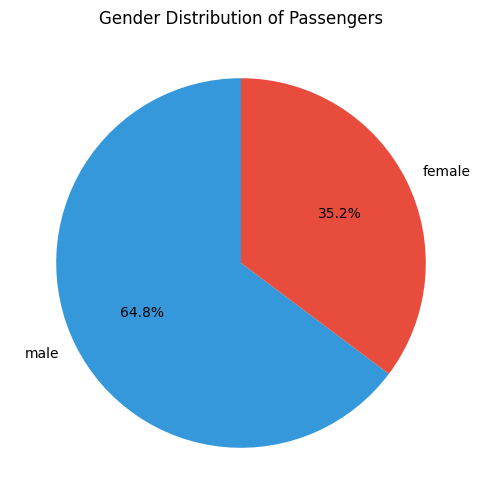

In [10]:
import matplotlib.pyplot as plt

# Calculate the gender distribution
gender_counts = df['Sex'].value_counts()

# Create a pie chart
plt.figure(figsize=(6, 6))
plt.pie(gender_counts, labels=gender_counts.index, autopct='%1.1f%%', startangle=90, colors=['#3498db', '#e74c3c'])
plt.title('Gender Distribution of Passengers')
plt.show()

### 1. Survival Rates by Demographics (Gender and Age)
We will calculate the precise survival percentages for each group and visualize the distributions.

/tmp/ipykernel_4397/359647739.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  gender_survival = df.groupby('Sex')['Survived'].value_counts(normalize=True).unstack() * 100


Survival Rate by Gender (%):
Survived          0          1
Sex                           
female    25.796178  74.203822
male      81.109185  18.890815


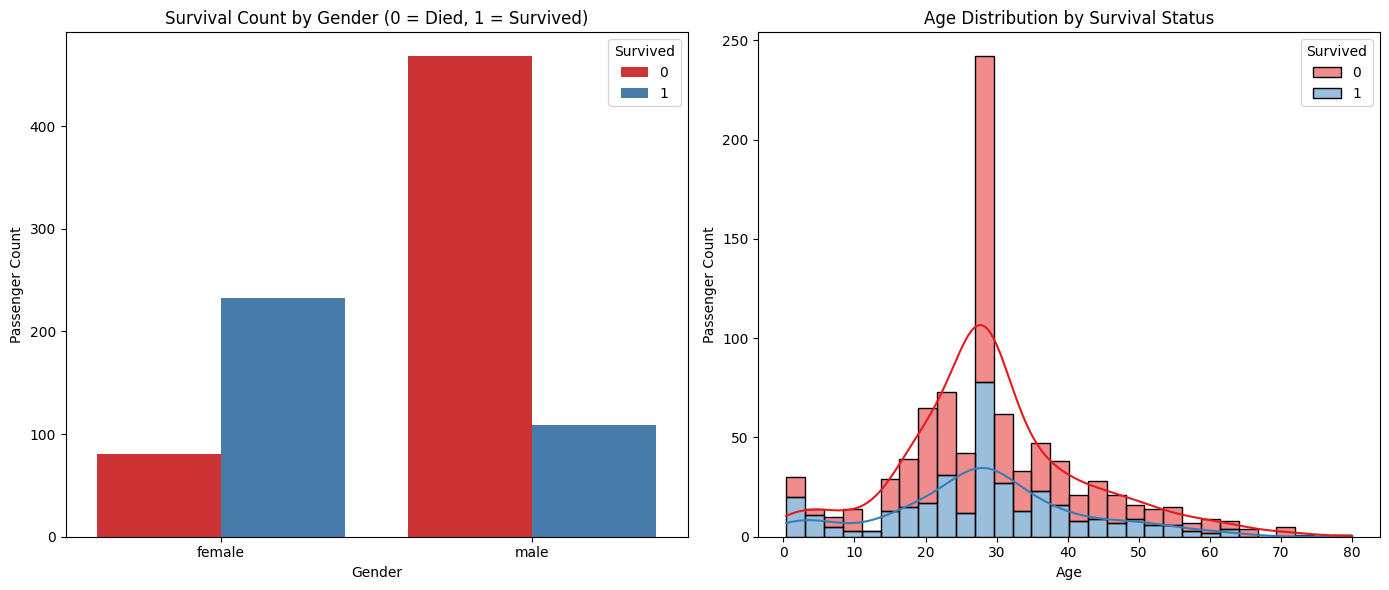

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate exact survival rate by Gender
gender_survival = df.groupby('Sex')['Survived'].value_counts(normalize=True).unstack() * 100
print("Survival Rate by Gender (%):")
print(gender_survival)

# Create subplots for visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Plot 1: Survival rate by Gender
sns.countplot(data=df, x='Sex', hue='Survived', palette='Set1', ax=axes[0])
axes[0].set_title('Survival Count by Gender (0 = Died, 1 = Survived)')
axes[0].set_xlabel('Gender')
axes[0].set_ylabel('Passenger Count')

# Plot 2: Age distribution by Survival Status
sns.histplot(data=df, x='Age', hue='Survived', multiple='stack', kde=True, palette='Set1', ax=axes[1])
axes[1].set_title('Age Distribution by Survival Status')
axes[1].set_xlabel('Age')
axes[1].set_ylabel('Passenger Count')

plt.tight_layout()
plt.show()

### 2. Survival Rates by Ticket Class (Pclass)
Let's analyze how passenger class (socio-economic status) impacted survival outcomes.

### 2.1 Stacked Survival Distribution by Class (including Total)
Let's visualize the survival split as a single stacked bar for each class, adding a combined 'Total' column.

Stacked Counts (by Pclass and Combined Total):


Survived,0,1
Pclass,,
1,80,136
2,97,87
3,372,119
Total,549,342


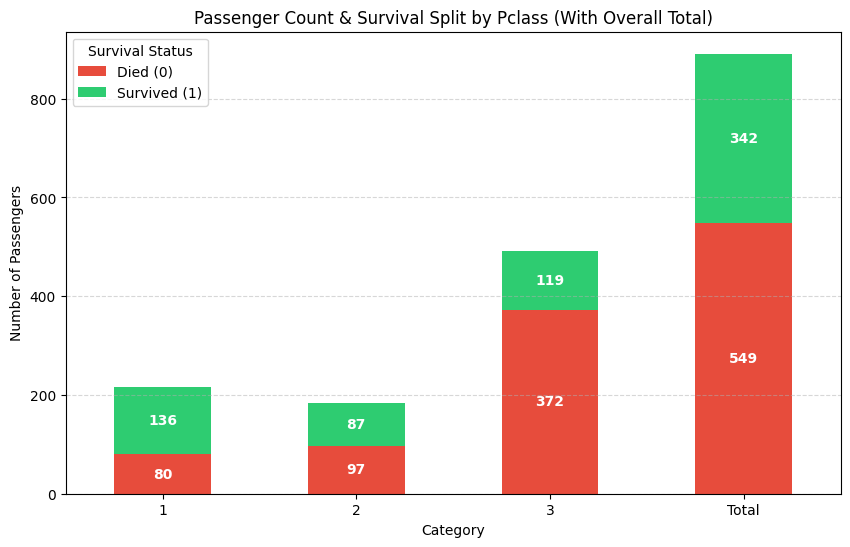

In [12]:
import matplotlib.pyplot as plt
import pandas as pd

# Prepare data for stacked bars including a 'Total' column
stacked_data = df.groupby(['Pclass', 'Survived'], observed=False).size().unstack(fill_value=0)

# Create a copy to append the 'Total' row
stacked_data_with_total = stacked_data.copy()
stacked_data_with_total.loc['Total'] = stacked_data.sum()

# Print the summary statistics
print("Stacked Counts (by Pclass and Combined Total):")
display(stacked_data_with_total)

# Plot the stacked bar chart
ax = stacked_data_with_total.plot(kind='bar', stacked=True, figsize=(10, 6), color=['#e74c3c', '#2ecc71'])

plt.title('Passenger Count & Survival Split by Pclass (With Overall Total)')
plt.xlabel('Category')
plt.ylabel('Number of Passengers')
plt.xticks(rotation=0)
plt.legend(['Died (0)', 'Survived (1)'], title='Survival Status')
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Add data labels inside the stacked bars for clarity
for rect in ax.patches:
    height = rect.get_height()
    width = rect.get_width()
    x = rect.get_x()
    y = rect.get_y()
    if height > 0:
        ax.text(x + width/2., y + height/2., f'{int(height)}',
                ha='center', va='center', color='white', fontweight='bold')

plt.show()

Discussion:

I explored how Gemini could help me analyse the Titanic dataset, from cleaning to drawing conclusions. It cleaned the data efficiently (dropping duplicates and the sparse Cabin column, imputing missing Age and Embarked values, and fixing data types). While I was deciding which factors to compare, it let me go a step further and show them graphically in an efficient way: gender split, survival by gender and age, and survival by ticket class. The charts suggest gender and class strongly affected survival (women survived at about 74% versus 19% for men, and first class far more than third). However, Gemini needs checking: median imputation created a spike in the age distribution, and the charts show correlation, not causation. Gemini sped up the coding, but the interpretation stayed with me.
